# 06 · Final Comparison and Model Selection

This notebook puts the best model of each approach side by side, adds a **hybrid**, and stress-tests them under
conditions a real-time Wi-Fi meter will face.

| Candidate | What it is |
|---|---|
| **Rule-based** | Physics baseline: nearest expected total power (+ PF term), no machine learning on combinations |
| **Model A** | Best snapshot classifier from notebook 04 (Extra Trees, `snapshot_plus` features) |
| **Model B v1** | Event tracker as first tuned in notebook 05 (power-sum check optional) |
| **Model B v2** | Event tracker after the fixes in notebook 05 (Decision Tree event classifier) |
| **Hybrid (B v2 + A)** | Model B v2, but its **start-up state and corrections come from Model A** instead of physics |

**Why a hybrid?** Model B is excellent while it sees every switch, but it must start from *some* state and needs a
way back after a missed switch. Plain Model B uses physics for that (closest consistent combination); the hybrid asks
Model A, which recognises most combinations from a single reading.

Evaluations:
1. **Cross-validation** (leave-one-block-out on the training blocks), all candidates re-evaluated the same way.
2. **Test block** (free household-style use).
3. **Robustness:** start-up in the middle of use, sensor noise, and lost Wi-Fi packets.
4. **Real-time cost:** time per sample and decision delay.

In [1]:
import sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import joblib

sys.path.insert(0, str(Path.cwd().parent))
from src.config import APPLIANCES, APPLIANCE_NAMES, FIGURES_DIR, MODELS_DIR
from src.data_loader import load_labelled, load_events
from src.features import build_features, FEATURE_SETS
from src.evaluation import score, labels_to_combo, combo_to_labels
from src.models import build_from_params
from src.event_model import block_sequences, event_training_table, make_tracker
from src.hybrid import ModelACorrector

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight"})
def save(fig, name): fig.savefig(FIGURES_DIR / f"{name}.png")
ROOT = Path.cwd().parent
COLORS = {"hair_dryer": "#d62728", "hair_straightener": "#9467bd", "bulb_200W": "#ff7f0e", "bulb_100W": "#2ca02c"}
SHORT = {"hair_dryer": "Dryer", "hair_straightener": "Straightener", "bulb_200W": "200W", "bulb_100W": "100W"}
CAND_COLORS = {"Rule-based": "#8c8c8c", "Model A": "#4c72b0", "Model B v1": "#dd8452",
               "Model B v2": "#55a868", "Hybrid (B v2 + A)": "#c44e52"}

df = load_labelled()
events = load_events()
seqs = block_sequences(df)
table = event_training_table(seqs, events, max_lag=3)
train_blocks = [b for b in seqs if b != "F_test"]

# tuned settings from notebooks 04 and 05
a_res = pd.read_csv(ROOT / "reports" / "model_a" / "tuning_results.csv")
rule_params = json.loads(a_res[a_res.model == "rule_based"].iloc[0].best_params)
meta_a = json.loads((MODELS_DIR / "model_a_best.json").read_text())
meta_b = json.loads((MODELS_DIR / "model_b_best.json").read_text())
b1_res = pd.read_csv(ROOT / "reports" / "model_b" / "v1" / "tuning_results.csv")
b1 = b1_res.iloc[0]            # v1 selected by CV
b1_params = json.loads(b1.best_params)
print("Model A :", meta_a["model_name"], meta_a["feature_set"])
print("Model B :", meta_b["classifier_name"], meta_b["params"])
print("Model B v1:", b1.classifier_name)

Model A : Extra Trees snapshot_plus
Model B : Decision Tree {'change_cost_W': 15.6065191493337, 'lag': 3, 'margin_W': 23.52488403577912, 'max_depth': 3, 'min_samples_leaf': 8, 'persist': 4, 'threshold_W': 25.07144482168826, 'tolerance_W': 54.45137646049899}
Model B v1: Decision Tree


## 1. One interface for all candidates

`fit_candidate(name, exclude_block)` trains a candidate on all training blocks except `exclude_block` (for CV) and
returns a function that maps a recording (raw power, current, PF) to an ON/OFF matrix. Every candidate computes its
own features from the raw readings, so noise and packet-loss tests treat all of them the same way.

In [2]:
def add_features(seq):
    F = build_features(seq.assign(source_file="seq"), group_col="source_file")
    return pd.concat([seq.reset_index(drop=True), F.drop(columns=["power_W", "current_A", "pf"]).reset_index(drop=True)],
                     axis=1)

# features per block (all features are causal and computed inside each recording block)
block_feats = {b: add_features(s) for b, s in seqs.items()}

def train_rows(exclude_block):
    keep = [b for b in train_blocks if b != exclude_block]
    return pd.concat([block_feats[b] for b in keep], ignore_index=True)

def fit_snapshot(model_key, params, feature_set, exclude_block):
    d = train_rows(exclude_block)
    cols = FEATURE_SETS[feature_set]
    m = build_from_params(model_key, params, "combo").fit(d[cols], labels_to_combo(d[APPLIANCES].to_numpy()))
    return m, cols

def fit_candidate(name, exclude_block=None):
    train_df = df[(df.split == "train") & (df.block != exclude_block)]
    tab = table[(table.block != exclude_block) & (table.block != "F_test")]
    if name == "Rule-based":
        m, cols = fit_snapshot("rule_based", rule_params, "snapshot_plus", exclude_block)
        return lambda seq: combo_to_labels(m.predict(add_features(seq)[cols]))
    if name == "Model A":
        m, cols = fit_snapshot(meta_a["model"], meta_a["params"], meta_a["feature_set"], exclude_block)
        return lambda seq: combo_to_labels(m.predict(add_features(seq)[cols]))
    if name == "Model B v1":
        trk = make_tracker(optuna.trial.FixedTrial(b1_params), b1.classifier, train_df, tab, version=1)
        return trk.run
    if name == "Model B v2":
        trk = make_tracker(optuna.trial.FixedTrial(meta_b["params"]), meta_b["classifier"], train_df, tab, version=2)
        return trk.run
    if name == "Hybrid (B v2 + A)":
        m, cols = fit_snapshot(meta_a["model"], meta_a["params"], meta_a["feature_set"], exclude_block)
        trk = make_tracker(optuna.trial.FixedTrial(meta_b["params"]), meta_b["classifier"], train_df, tab,
                           corrector=ModelACorrector(m, cols), version=2)
        return trk.run
    raise ValueError(name)

CANDIDATES = list(CAND_COLORS)

## 2. Cross-validation (leave-one-block-out, training blocks)

In [3]:
cv_rows = []
for name in CANDIDATES:
    Y, P = [], []
    for b in train_blocks:
        predict = fit_candidate(name, exclude_block=b)
        Y.append(seqs[b][APPLIANCES].to_numpy(int)); P.append(predict(seqs[b]))
    cv_rows.append({"candidate": name, **{f"cv_{k}": v for k, v in score(np.vstack(Y), np.vstack(P)).items()}})
cv = pd.DataFrame(cv_rows).set_index("candidate")
cv[["cv_exact_match", "cv_macro_f1", "cv_acc_hair_straightener", "cv_acc_bulb_100W"]].round(3)

,cv_exact_match,cv_macro_f1,cv_acc_hair_straightener,cv_acc_bulb_100W
candidate,,,,
Rule-based,0.842,0.861,0.858,0.852
Model A,0.898,0.912,0.910,0.903
Model B v1,0.927,0.942,0.936,0.949
Model B v2,0.939,0.951,0.949,0.963
Hybrid (B v2 + A),0.939,0.951,0.949,0.963


## 3. Test block

In [4]:
test_seq = seqs["F_test"]
y_te = test_seq[APPLIANCES].to_numpy(int)
fitted = {name: fit_candidate(name) for name in CANDIDATES}
test_pred = {name: fitted[name](test_seq) for name in CANDIDATES}
te = pd.DataFrame([{"candidate": n, **{f"test_{k}": v for k, v in score(y_te, p).items()}}
                   for n, p in test_pred.items()]).set_index("candidate")
summary = cv[["cv_exact_match"]].join(te[["test_exact_match", "test_macro_f1"] +
                                         [f"test_acc_{a}" for a in APPLIANCES]])
summary.round(3)

,cv_exact_match,test_exact_match,test_macro_f1,test_acc_hair_dryer,test_acc_hair_straightener,test_acc_bulb_200W,test_acc_bulb_100W
candidate,,,,,,,
Rule-based,0.842,0.716,0.879,1.000,0.743,0.962,0.716
Model A,0.898,0.798,0.918,1.000,0.836,0.973,0.798
Model B v1,0.927,0.393,0.851,0.814,0.716,0.765,0.913
Model B v2,0.939,0.984,0.994,1.000,0.984,0.984,1.000
Hybrid (B v2 + A),0.939,0.984,0.994,1.000,0.984,0.984,1.000


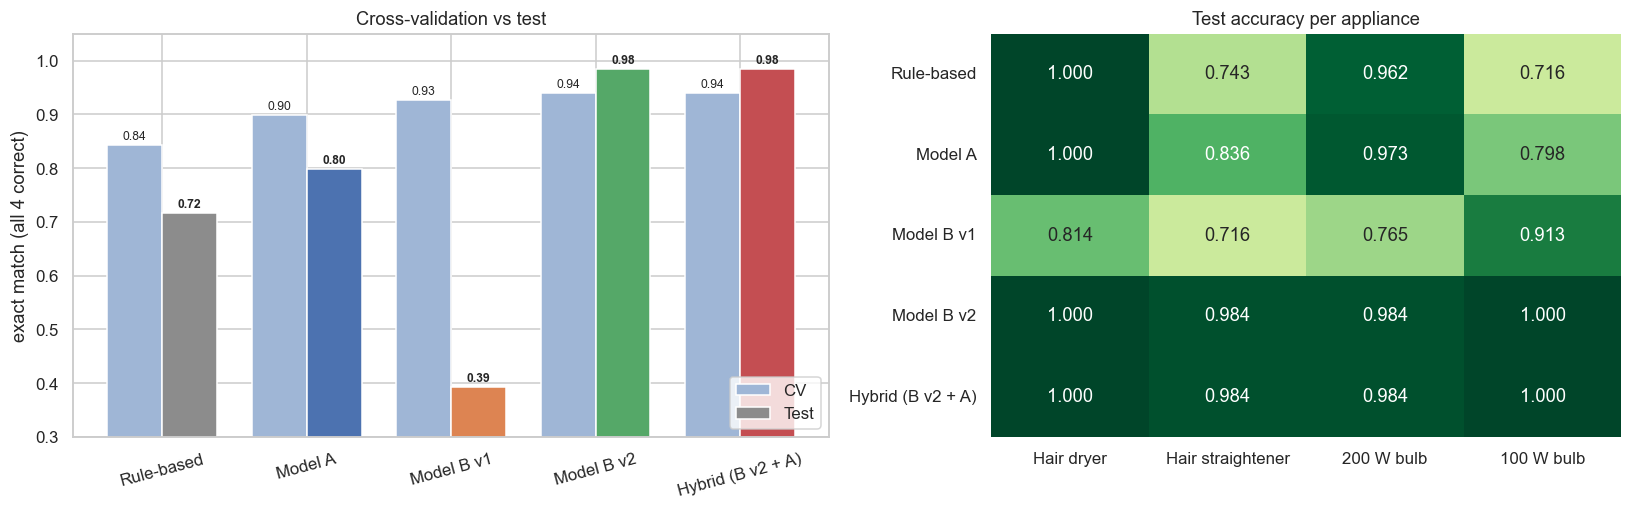

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
x = np.arange(len(CANDIDATES)); w = 0.38
axes[0].bar(x - w / 2, summary.cv_exact_match, w, label="CV", color="#9fb6d6")
axes[0].bar(x + w / 2, summary.test_exact_match, w, label="Test", color=[CAND_COLORS[c] for c in CANDIDATES])
for i, (c, t) in enumerate(zip(summary.cv_exact_match, summary.test_exact_match)):
    axes[0].text(i - w / 2, c + 0.01, f"{c:.2f}", ha="center", fontsize=8)
    axes[0].text(i + w / 2, t + 0.01, f"{t:.2f}", ha="center", fontsize=8, fontweight="bold")
axes[0].set_xticks(x); axes[0].set_xticklabels(CANDIDATES, rotation=15)
axes[0].set_ylim(0.3, 1.05); axes[0].set_ylabel("exact match (all 4 correct)")
axes[0].set_title("Cross-validation vs test"); axes[0].legend(loc="lower right")
per = summary[[f"test_acc_{a}" for a in APPLIANCES]]
per.columns = [APPLIANCE_NAMES[a] for a in APPLIANCES]
sns.heatmap(per, annot=True, fmt=".3f", cmap="YlGn", vmin=0.6, vmax=1.0, ax=axes[1], cbar=False)
axes[1].set_title("Test accuracy per appliance"); axes[1].set_ylabel("")
fig.tight_layout(); save(fig, "33_final_comparison"); plt.show()

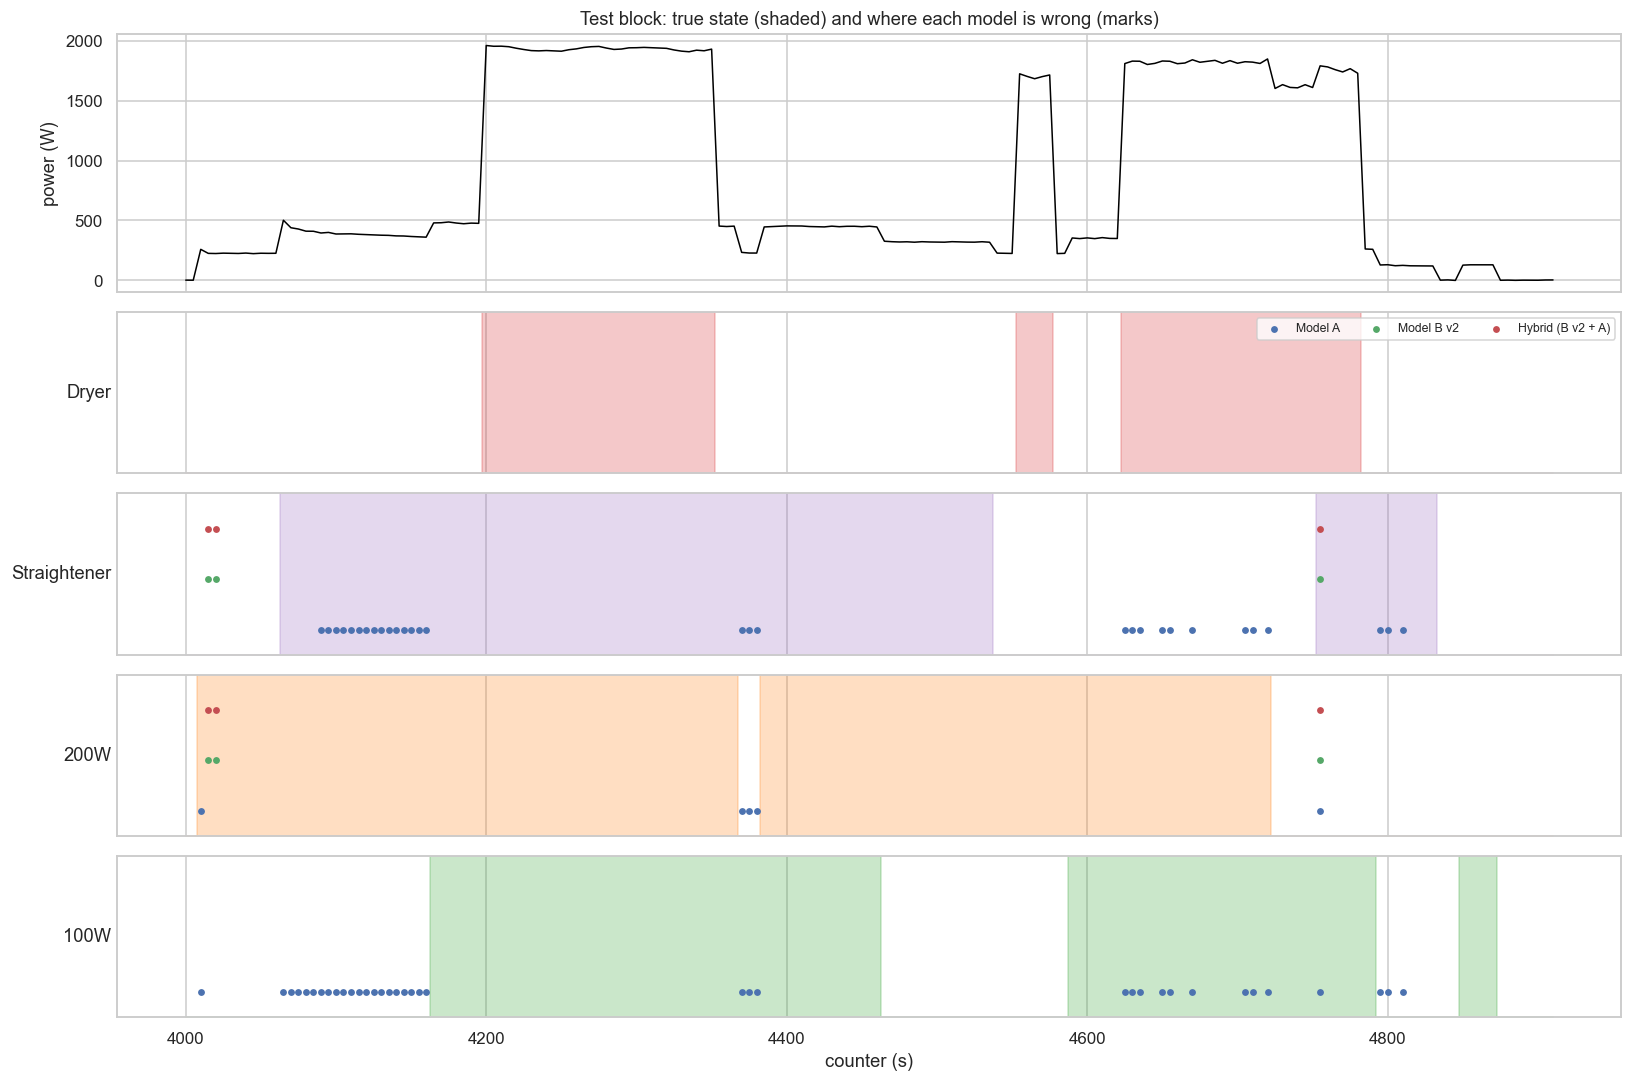

In [6]:
fig, axes = plt.subplots(1 + 4, 1, figsize=(15, 10), sharex=True, gridspec_kw={"height_ratios": [1.6, 1, 1, 1, 1]})
t = test_seq.counter.values
axes[0].plot(t, test_seq.power_W, color="black", lw=1); axes[0].set_ylabel("power (W)")
axes[0].set_title("Test block: true state (shaded) and where each model is wrong (marks)")
show = ["Model A", "Model B v2", "Hybrid (B v2 + A)"]
for k, a in enumerate(APPLIANCES):
    ax = axes[k + 1]
    ax.fill_between(t, 0, y_te[:, k] * 3.2, step="mid", color=COLORS[a], alpha=0.25)
    for j, name in enumerate(show):
        wrong = test_pred[name][:, k] != y_te[:, k]
        ax.scatter(t[wrong], np.full(wrong.sum(), 0.5 + j), color=CAND_COLORS[name], s=12,
                   label=name if k == 0 else None)
    ax.set_ylim(0, 3.2); ax.set_yticks([]); ax.set_ylabel(SHORT[a], rotation=0, ha="right", va="center")
axes[1].legend(loc="upper right", fontsize=8, ncol=3)
axes[-1].set_xlabel("counter (s)")
fig.tight_layout(); save(fig, "34_final_test_errors"); plt.show()

## 4. Robustness tests

These tests perturb the **test block** to mimic real deployment conditions. They compare candidates under stress;
they are not used to tune anything.

### 4.1 Start-up in the middle of use

In real life the meter (or the Wi-Fi link) can restart while appliances are already ON. Here each model starts
tracking at a different point of the test block (every 5 samples) with no history at all.

In [7]:
offsets = list(range(0, len(test_seq) - 30, 5))
cs_rows = []
for name in CANDIDATES:
    for k in offsets:
        sub = test_seq.iloc[k:].reset_index(drop=True)
        p = fitted[name](sub)
        ok = (p == sub[APPLIANCES].to_numpy(int)).all(axis=1)
        cs_rows.append({"candidate": name, "start_counter": int(test_seq.counter.iloc[k]),
                        "exact_match_rest": ok.mean(), "exact_match_first_2min": ok[:24].mean()})
cold = pd.DataFrame(cs_rows)
cold_summary = cold.groupby("candidate", sort=False)[["exact_match_first_2min", "exact_match_rest"]].agg(["mean", "min"])
cold_summary.round(3)

exact_match_first_2min        exact_match_rest       
                                    mean    min             mean    min
candidate                                                              
Rule-based                         0.688  0.167            0.715  0.586
Model A                            0.784  0.167            0.846  0.776
Model B v1                         0.347  0.000            0.194  0.020
Model B v2                         0.558  0.000            0.844  0.446
Hybrid (B v2 + A)                  0.833  0.000            0.944  0.534

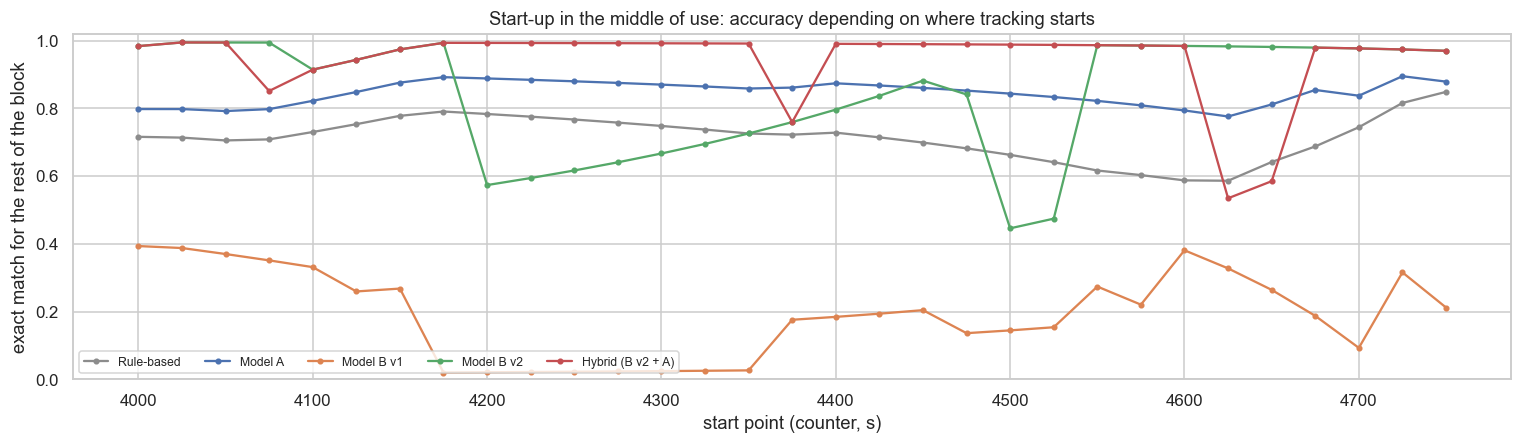

In [8]:
fig, ax = plt.subplots(figsize=(14, 4.2))
for name in CANDIDATES:
    g = cold[cold.candidate == name]
    ax.plot(g.start_counter, g.exact_match_rest, marker="o", ms=3, label=name, color=CAND_COLORS[name])
ax.set_xlabel("start point (counter, s)"); ax.set_ylabel("exact match for the rest of the block")
ax.set_title("Start-up in the middle of use: accuracy depending on where tracking starts")
ax.legend(fontsize=8, ncol=5, loc="lower left"); ax.set_ylim(0, 1.02)
fig.tight_layout(); save(fig, "35_cold_start"); plt.show()

Model A has no memory, so where it starts does not matter. Plain Model B v2 has to *guess* its starting state with
physics, and when it starts during a look-alike combination (e.g. *Straightener + 200W* vs *200W + 100W*) that guess
can be wrong and stay wrong until the next switch of the wrongly-guessed appliance. The hybrid starts from Model A's
prediction, which is right far more often, and then keeps Model B's event accuracy.

### 4.2 Sensor noise

How noisy is the real meter? Sample-to-sample spread of the power in steady states (no switch, straightener excluded
because it drifts while heating):

In [9]:
d = df.sort_values(["run", "counter"]).copy()
d["dP"] = d.groupby("source_file", observed=True).power_W.diff()
steady_rows = d[(d.combo == d.groupby("source_file", observed=True).combo.shift()) & (d.transition == 0)
                & (d.hair_straightener == 0) & (d.dryer_medium_setting == 0)]
real_noise = (steady_rows.groupby(steady_rows.hair_dryer.map({0: "dryer OFF", 1: "dryer ON"}))
              .dP.std().div(np.sqrt(2)).rename("noise per sample (W)").to_frame())
real_noise.round(1)

,noise per sample (W)
hair_dryer,
dryer OFF,1.5
dryer ON,12.9


The real noise is ≈ 1.5–3 W with only bulbs on and ≈ 12–14 W when the dryer is on (the dryer itself wobbles). The
test below adds noise **on top of** that:

extra Gaussian noise on every reading (power σ as shown, current σ = power σ / 245 V,
PF σ = power σ / 2000), 5 random seeds per level.

In [10]:
rng_seeds = [0, 1, 2, 3, 4]
noise_levels = [0, 5, 10, 20, 40]
nz_rows = []
for sigma in noise_levels:
    for seed in (rng_seeds if sigma else [0]):
        rng = np.random.default_rng(seed)
        noisy = test_seq.copy()
        noisy["power_W"] = noisy.power_W + rng.normal(0, sigma, len(noisy))
        noisy["current_A"] = (noisy.current_A + rng.normal(0, sigma / 245, len(noisy))).clip(lower=0)
        noisy["pf"] = (noisy.pf + rng.normal(0, sigma / 2000, len(noisy))).clip(-1, 1)
        for name in CANDIDATES:
            nz_rows.append({"candidate": name, "sigma_W": sigma, "seed": seed,
                            "exact_match": score(y_te, fitted[name](noisy))["exact_match"]})
noise = pd.DataFrame(nz_rows).groupby(["candidate", "sigma_W"], sort=False).exact_match.mean().unstack()
noise.round(3)

sigma_W,0,5,10,20,40
candidate,,,,,
Rule-based,0.716,0.725,0.713,0.698,0.590
Model A,0.798,0.789,0.734,0.679,0.611
Model B v1,0.393,0.284,0.286,0.212,0.146
Model B v2,0.984,0.909,0.713,0.295,0.101
Hybrid (B v2 + A),0.984,0.881,0.662,0.319,0.119


### 4.3 Lost Wi-Fi packets

A share of the readings is dropped at random (the model never sees them); accuracy is measured on the readings that
arrive. 5 random seeds per level.

In [11]:
loss_levels = [0, 0.05, 0.10, 0.20]
pl_rows = []
for loss in loss_levels:
    for seed in (rng_seeds if loss else [0]):
        rng = np.random.default_rng(100 + seed)
        keep = rng.random(len(test_seq)) >= loss
        keep[0] = True
        sub = test_seq[keep].reset_index(drop=True)
        for name in CANDIDATES:
            pl_rows.append({"candidate": name, "loss": loss, "seed": seed,
                            "exact_match": score(sub[APPLIANCES].to_numpy(int), fitted[name](sub))["exact_match"]})
loss_tab = pd.DataFrame(pl_rows).groupby(["candidate", "loss"], sort=False).exact_match.mean().unstack()
loss_tab.round(3)

loss,0.00,0.05,0.10,0.20
candidate,,,,
Rule-based,0.716,0.718,0.716,0.717
Model A,0.798,0.798,0.795,0.797
Model B v1,0.393,0.357,0.356,0.324
Model B v2,0.984,0.971,0.970,0.957
Hybrid (B v2 + A),0.984,0.956,0.956,0.928


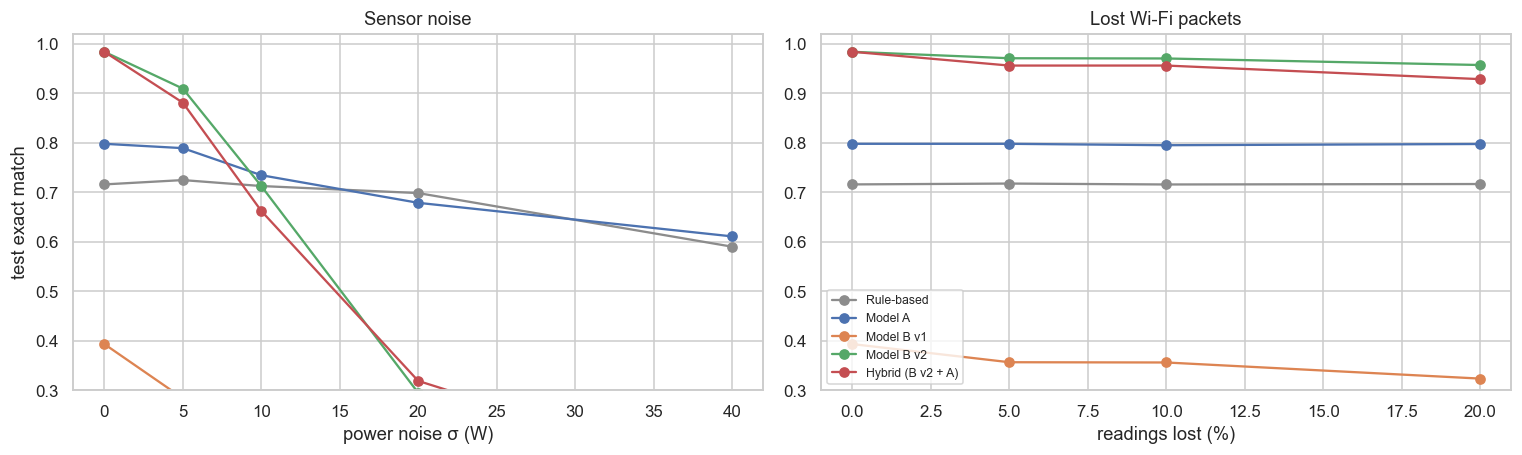

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for name in CANDIDATES:
    axes[0].plot(noise.columns, noise.loc[name], marker="o", label=name, color=CAND_COLORS[name])
    axes[1].plot([l * 100 for l in loss_tab.columns], loss_tab.loc[name], marker="o", label=name, color=CAND_COLORS[name])
axes[0].set_xlabel("power noise σ (W)"); axes[0].set_ylabel("test exact match"); axes[0].set_title("Sensor noise")
axes[1].set_xlabel("readings lost (%)"); axes[1].set_title("Lost Wi-Fi packets")
for ax in axes:
    ax.set_ylim(0.3, 1.02)
axes[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "36_noise_and_packet_loss"); plt.show()

## 5. Real-time cost

In [13]:
lat_rows = []
for name in CANDIDATES:
    lat = []
    sub = test_seq
    for k in range(5):                       # whole-block timing, averaged per sample
        t0 = time.perf_counter(); fitted[name](sub); lat.append((time.perf_counter() - t0) / len(sub))
    lat_rows.append({"candidate": name, "time_per_sample_ms": np.median(lat) * 1000})
latency = pd.DataFrame(lat_rows).set_index("candidate")
latency["decision_delay"] = ["none", "none", f"{int(b1_params['lag']) * 5} s",
                             f"{int(meta_b['params']['lag']) * 5} s", f"{int(meta_b['params']['lag']) * 5} s"]
latency["needs history"] = ["no", "no", "yes", "yes", "yes"]
latency.round(3)

,time_per_sample_ms,decision_delay,needs history
candidate,,,
Rule-based,0.248,none,no
Model A,0.413,none,no
Model B v1,0.336,15 s,yes
Model B v2,0.454,15 s,yes
Hybrid (B v2 + A),0.620,15 s,yes


Time per sample includes feature computation (for Model A in batch, so it is the per-sample share of a batch call;
a single live prediction of the Extra Trees takes ≈ 24 ms, see notebook 04). Every candidate is far below the
5-second (or 1-second) interval between readings. The event-based models give a provisional answer immediately and
a final one after the decision delay.

## 6. Final scorecard and selection

In [14]:
score_card = summary[["cv_exact_match", "test_exact_match"]].copy()
score_card["cold_start_mean"] = cold.groupby("candidate", sort=False).exact_match_rest.mean()
score_card["cold_start_worst"] = cold.groupby("candidate", sort=False).exact_match_rest.min()
score_card["noise_20W"] = noise[20]
score_card["packet_loss_10pct"] = loss_tab[0.10]
score_card.round(3)

,cv_exact_match,test_exact_match,cold_start_mean,cold_start_worst,noise_20W,packet_loss_10pct
candidate,,,,,,
Rule-based,0.842,0.716,0.715,0.586,0.698,0.716
Model A,0.898,0.798,0.846,0.776,0.679,0.795
Model B v1,0.927,0.393,0.194,0.020,0.212,0.356
Model B v2,0.939,0.984,0.844,0.446,0.295,0.970
Hybrid (B v2 + A),0.939,0.984,0.944,0.534,0.319,0.956


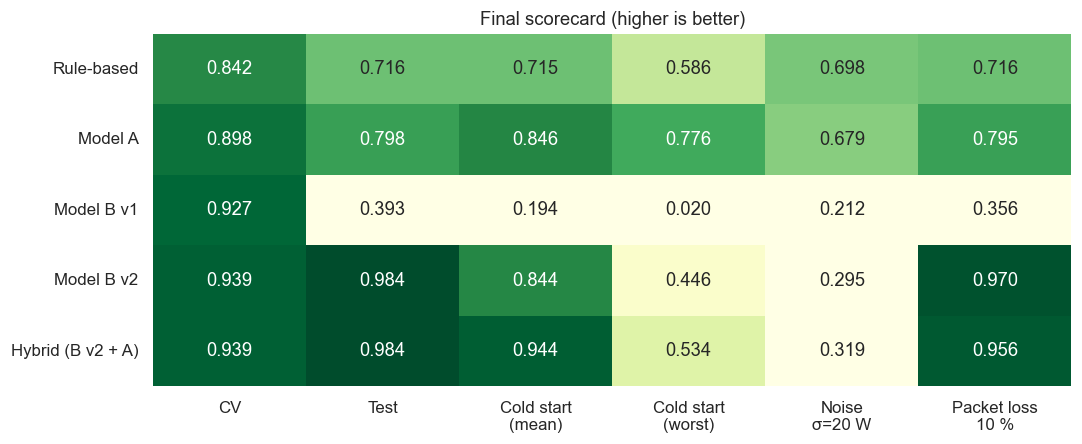

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.heatmap(score_card, annot=True, fmt=".3f", cmap="YlGn", vmin=0.4, vmax=1.0, ax=ax, cbar=False)
ax.set_title("Final scorecard (higher is better)"); ax.set_ylabel("")
ax.set_xticklabels(["CV", "Test", "Cold start\n(mean)", "Cold start\n(worst)", "Noise\nσ=20 W", "Packet loss\n10 %"])
fig.tight_layout(); save(fig, "37_final_scorecard"); plt.show()

**Selection rule:** pick the best cross-validation score; if candidates tie (within 0.005), prefer the one that is
more robust in the stress tests, because the model will run unattended in real time. The test block is not part of
the rule (it was already used to diagnose Model B v1).

In [16]:
best_cv = score_card.cv_exact_match.max()
tied = score_card[np.isclose(score_card.cv_exact_match, best_cv, atol=0.005)]
chosen = tied.sort_values(["cold_start_mean", "noise_20W", "packet_loss_10pct"], ascending=False).index[0]
print("Best CV score:", round(best_cv, 3), "| candidates within 0.005:", list(tied.index))
print("Selected final model:", chosen)
score_card.loc[chosen].round(3)

Best CV score: 0.939 | candidates within 0.005: ['Model B v2', 'Hybrid (B v2 + A)']
Selected final model: Hybrid (B v2 + A)


cv_exact_match       0.939
test_exact_match     0.984
cold_start_mean      0.944
cold_start_worst     0.534
noise_20W            0.319
packet_loss_10pct    0.956
Name: Hybrid (B v2 + A), dtype: float64

## 7. Save the final model

In [17]:
assert chosen == "Hybrid (B v2 + A)", "update the saving code if another candidate is selected"
m, cols = fit_snapshot(meta_a["model"], meta_a["params"], meta_a["feature_set"], None)
final_model = make_tracker(optuna.trial.FixedTrial(meta_b["params"]), meta_b["classifier"],
                           df[df.split == "train"], table[table.block != "F_test"],
                           corrector=ModelACorrector(m, cols), version=2)
check = final_model.run(test_seq)
assert (check == test_pred[chosen]).all()
final_model.reset()
joblib.dump(final_model, MODELS_DIR / "final_model.joblib")
final_meta = {
    "name": chosen,
    "description": "Event-based tracker (Model B v2) whose start-up state and power-sum corrections come from Model A",
    "model_b": meta_b, "model_a": {k: meta_a[k] for k in ("model", "model_name", "feature_set", "features", "params")},
    "input": ["power_W", "current_A", "pf"], "sample_period_s": 5,
    "output": APPLIANCES,
    "scores": {k: float(v) for k, v in score_card.loc[chosen].items()},
}
(MODELS_DIR / "final_model.json").write_text(json.dumps(final_meta, indent=2))
score_card.to_csv(ROOT / "reports" / "final_scorecard.csv")
print("Saved models/final_model.joblib and models/final_model.json")

Saved models/final_model.joblib and models/final_model.json


## Summary

**Final model: Hybrid (Model B v2 + Model A)**, saved as `models/final_model.joblib` (+ `final_model.json`).

| | Rule-based | Model A | Model B v1 | Model B v2 | **Hybrid** |
|---|---|---|---|---|---|
| CV exact match | 0.842 | 0.898 | 0.927 | 0.939 | **0.939** |
| Test exact match | 0.716 | 0.798 | 0.393 | 0.984 | **0.984** |
| Start-up mid-use (mean) | 0.715 | 0.846 | 0.194 | 0.844 | **0.944** |
| Extra noise σ = 5 W | 0.725 | 0.789 | 0.284 | 0.909 | 0.881 |
| Extra noise σ = 20 W | 0.698 | 0.679 | 0.212 | 0.295 | 0.319 |
| 10 % packets lost | 0.716 | 0.795 | 0.356 | 0.970 | 0.956 |

*(Model A's CV score here is 0.898 instead of 0.901 in notebook 04 because features are now computed inside each
block, as they would be live.)*

**Why the hybrid:** Model B v2 and the hybrid tie on CV and test, because during normal tracking the hybrid behaves
exactly like Model B. The difference is **start-up**: when tracking starts while appliances are already ON (a reboot,
a Wi-Fi reconnect), plain Model B guesses its initial state from physics and is wrong for look-alike combinations,
while the hybrid asks Model A (0.94 vs 0.84 on average). It costs a little under packet loss (0.956 vs 0.970), when
Model A's corrections are occasionally wrong for a look-alike combination.

**What to keep in mind**
- **Event-based models need clean switches.** With up to ≈ 5 W of extra noise they stay around 0.88–0.91, but with
  much more (σ ≥ 10 W) they fire false events and fall below Model A. The real meter is quiet (≈ 1.5–3 W, ≈ 13 W with
  the dryer), so this matters only for a noisier installation. Remedies: average the live 1-second readings into
  5-second means instead of keeping every 5th sample (√5 ≈ 2.2× less noise), or raise the detection threshold.
- **Packet loss is handled well** by the event models (≈ 0.96 at 10–20 % loss).
- **The test score of Model B v2 / hybrid is optimistic.** The v2 rules were prompted by the test block (notebook 05).
  A new recording of free household use is the next step for an independent estimate.
- One recording day, one house, 5-second resolution: more data (other days, more straightener restarts, other dryer
  settings) would make every model more reliable.

**Next: real-time inference over Wi-Fi** (`realtime/`), using `models/final_model.joblib` and the same parser and
5-second grid as the training data.